# Instrução do Projeto

A Film Junky Union, uma nova comunidade para entusiastas de filmes clássicos, está desenvolvendo um sistema para filtrar e categorizar resenhas de filmes. O objetivo é treinar um modelo para detectar automaticamente resenhas negativas. Você usará um conjunto de dados de resenhas de filmes do IMDB com rotulagem de polaridade para criar um modelo para classificar resenhas como positivas e negativas. Ele precisará ter um valor F1 de pelo menos 0,85.

## Inicialização

In [1]:
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import re

from tqdm.auto import tqdm

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# a próxima linha fornece gráficos de melhor qualidade em telas HiDPI
%config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn')

In [3]:
# isso é para usar progress_apply, leia mais em https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Carregar Dados

In [4]:
df_reviews = pd.read_csv('/datasets/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

## AED

Vamos verificar o número de filmes e resenhas ao longo dos anos.

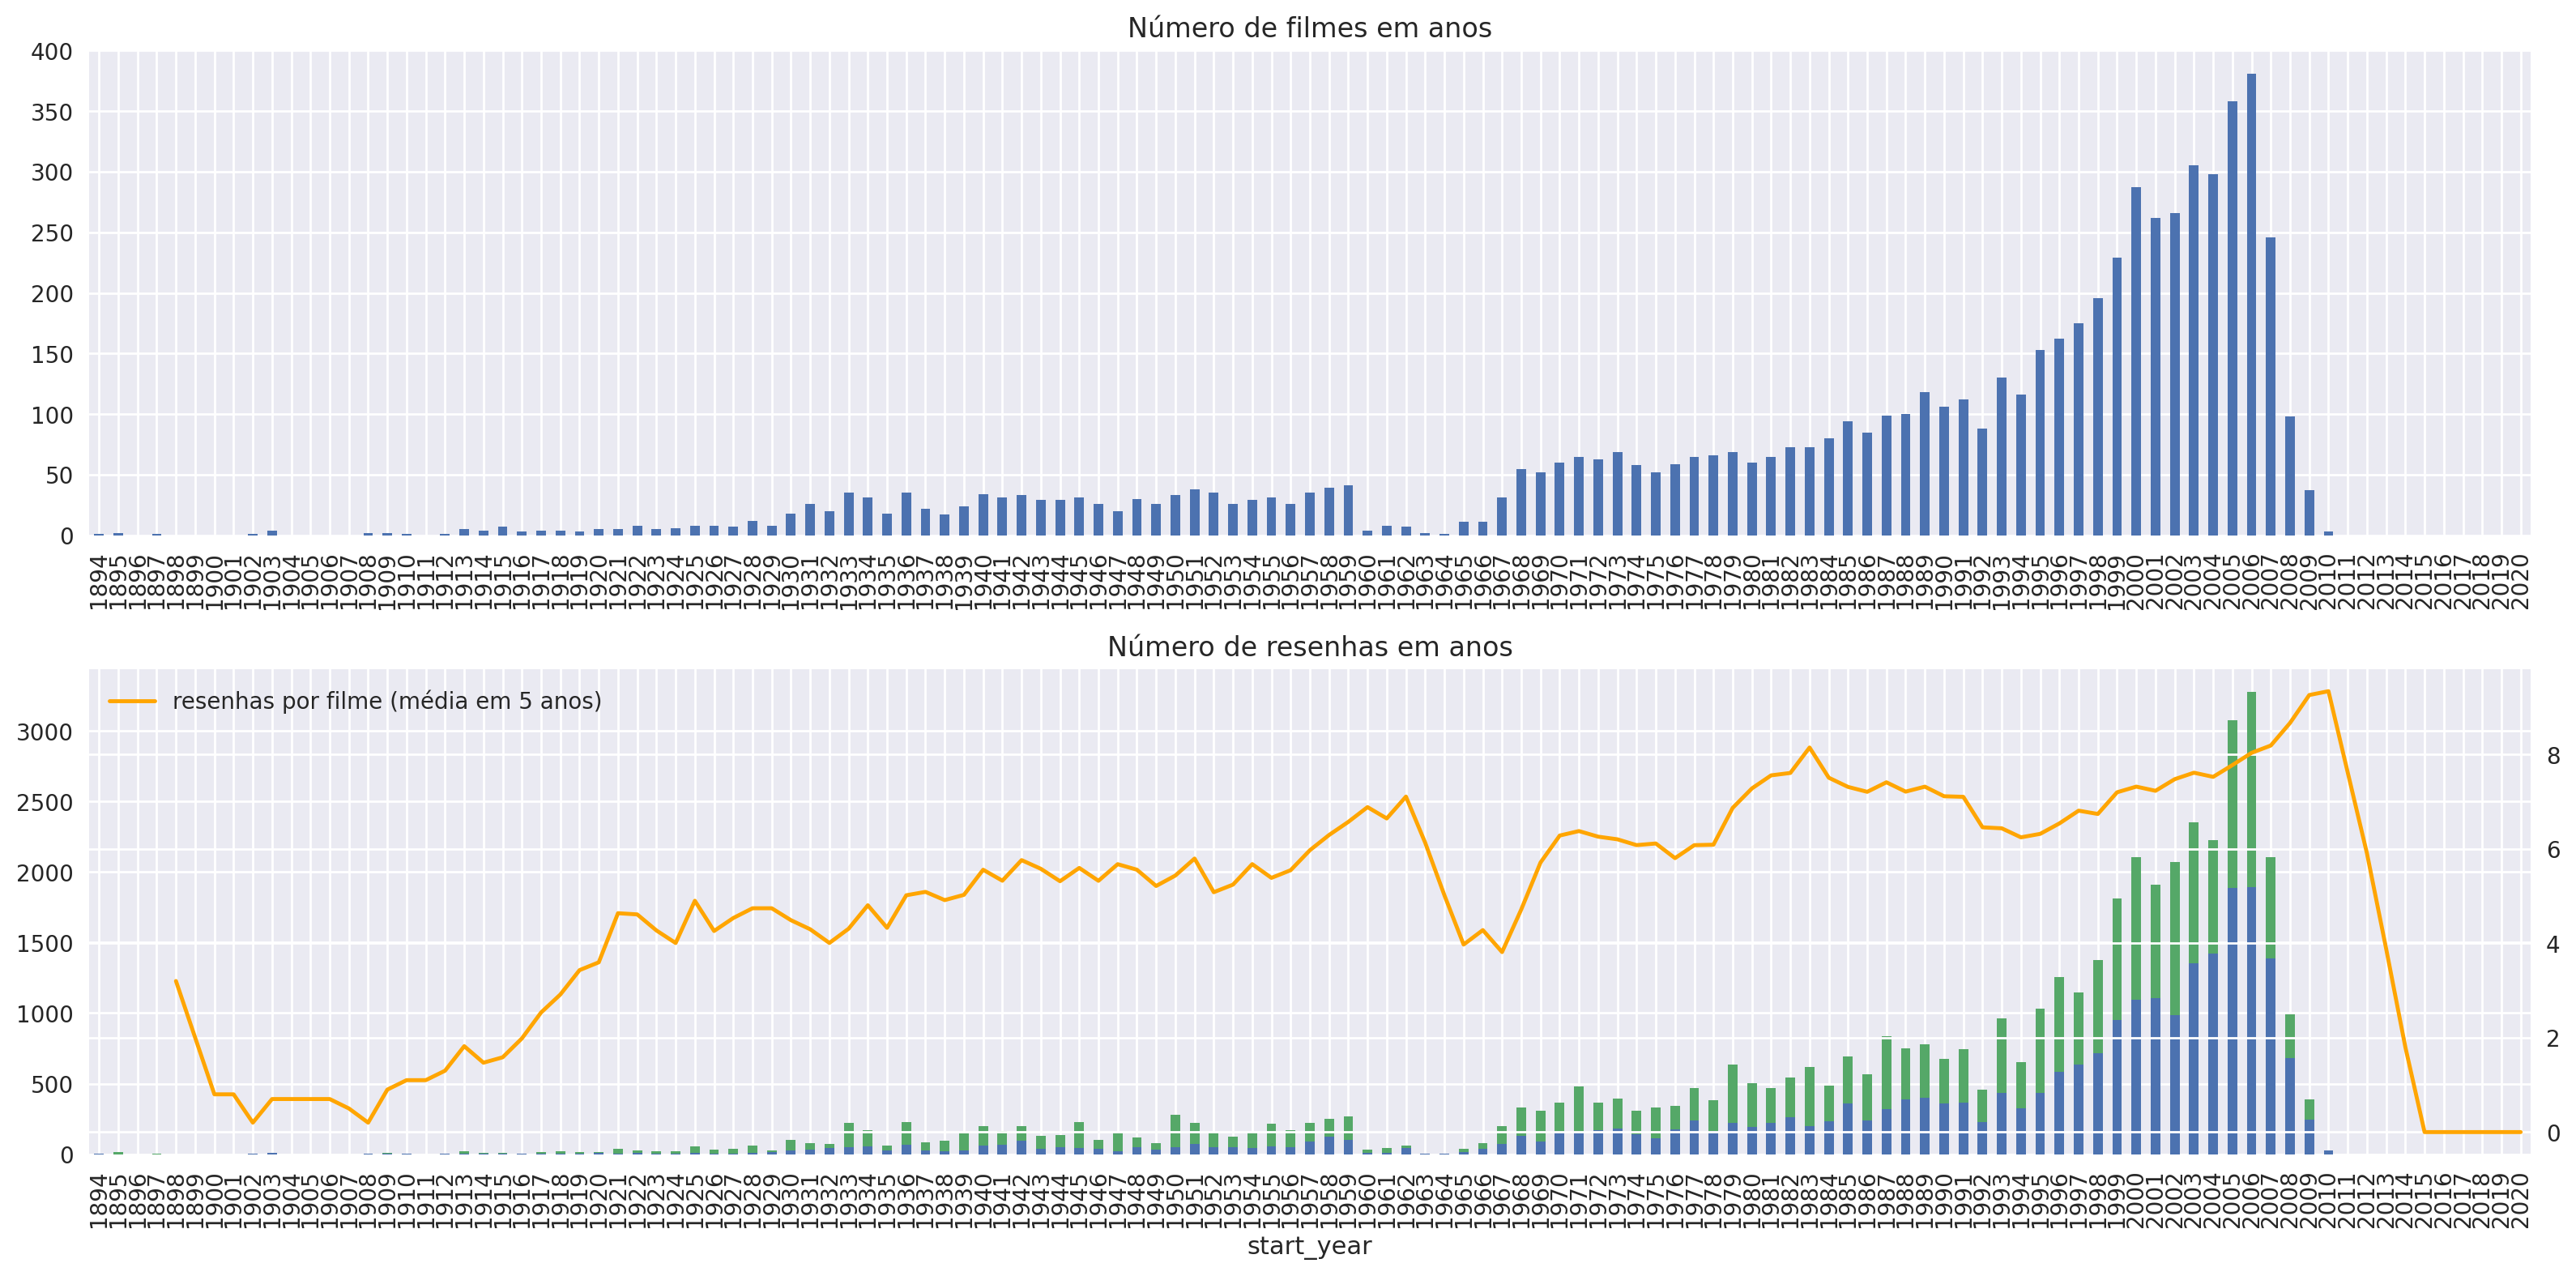

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de filmes em anos')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='resenhas por filme (média em 5 anos)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de resenhas em anos')

fig.tight_layout()

Vamos verificar a distribuição do número de resenhas por filme com a contagem exata e o EDK (Estimativa de densidade kernel - só para saber como pode diferir da contagem exata)

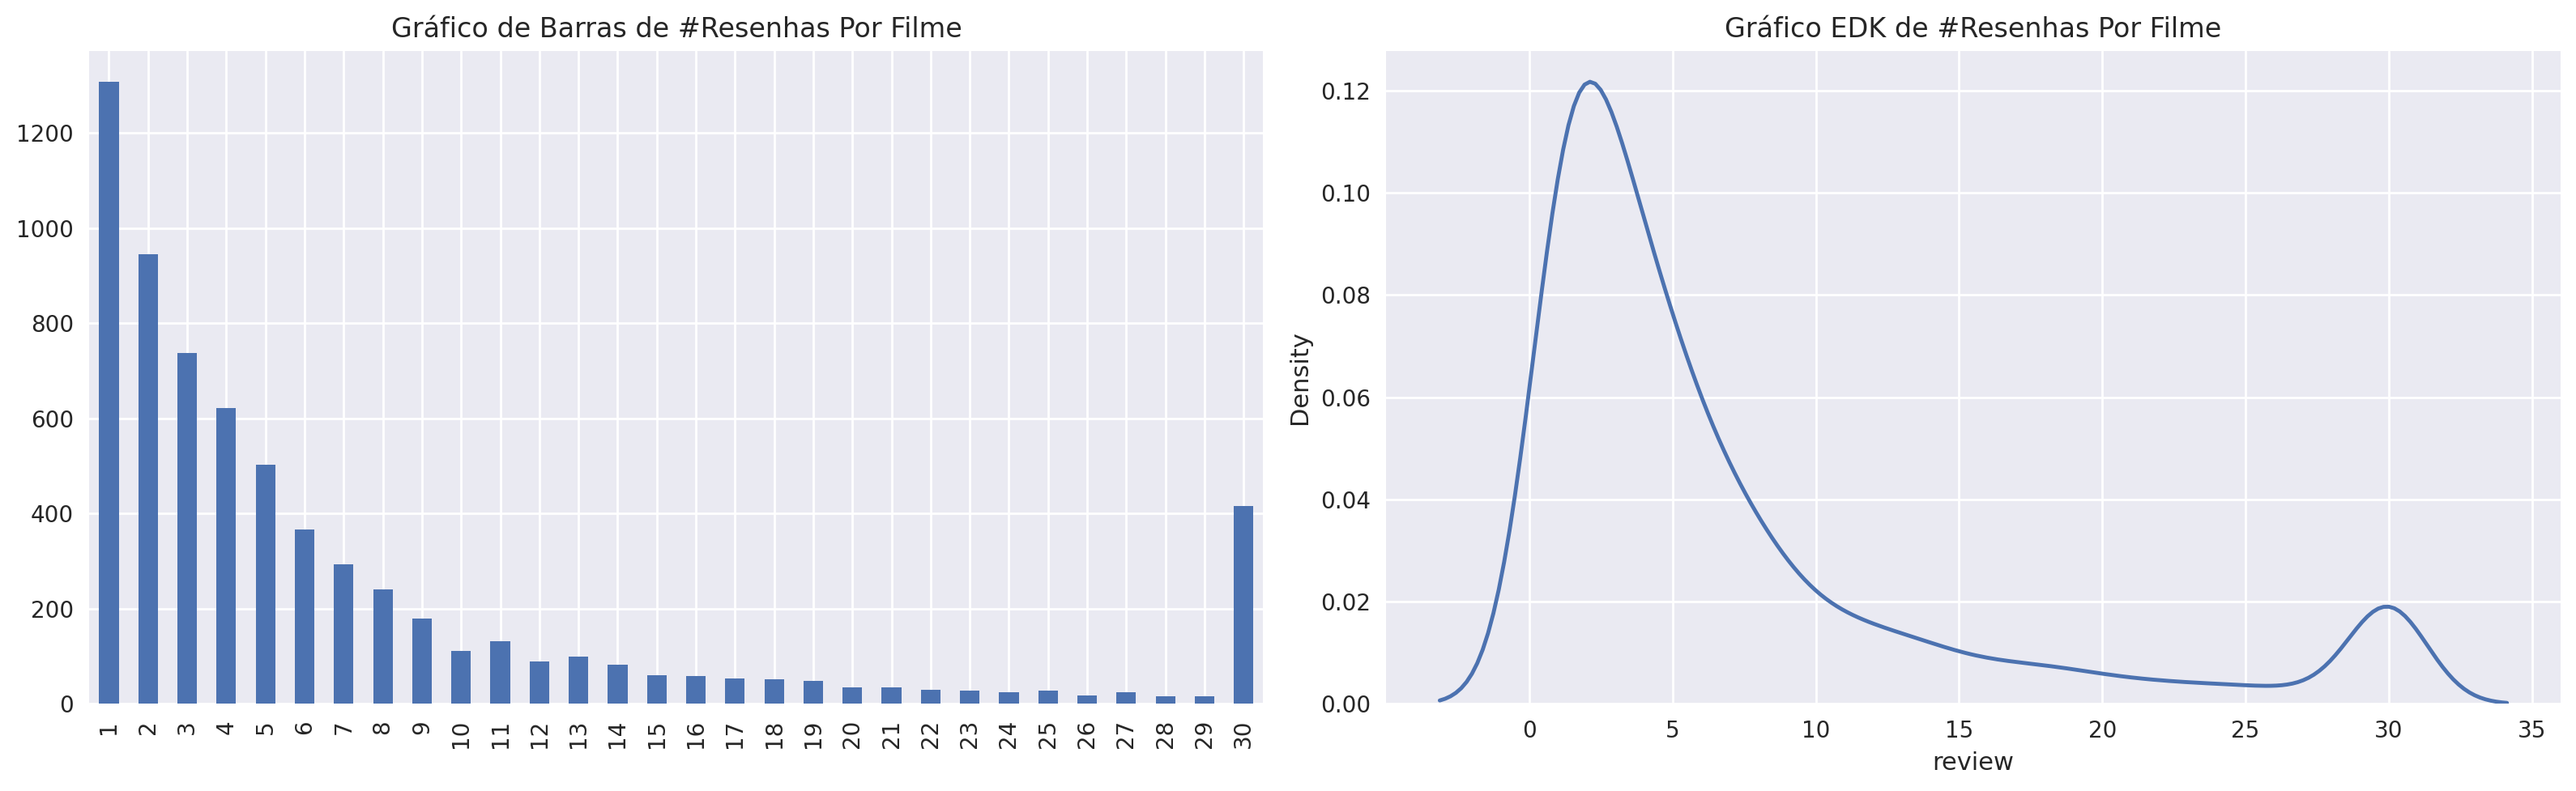

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de Barras de #Resenhas Por Filme')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico EDK de #Resenhas Por Filme')

fig.tight_layout()

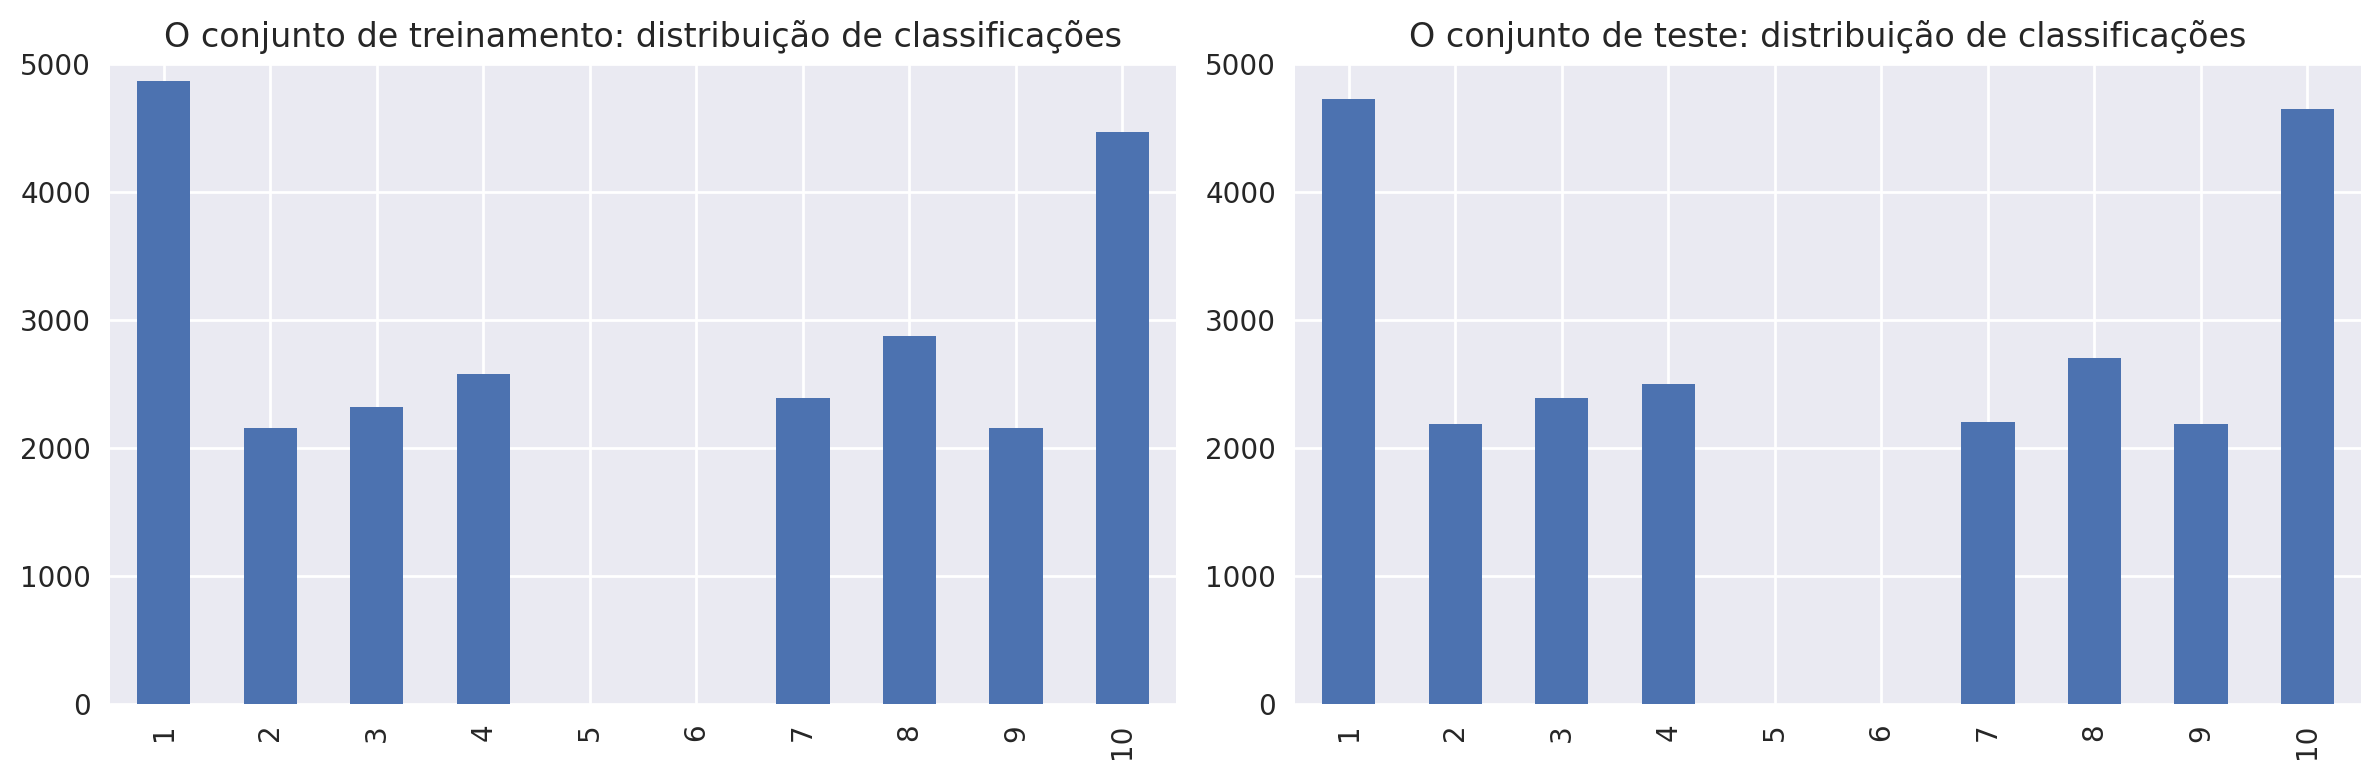

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de treinamento: distribuição de classificações')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de teste: distribuição de classificações')

fig.tight_layout()

Distribuição de resenhas negativas e positivas ao longo dos anos para duas partes do conjunto de dados

/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)


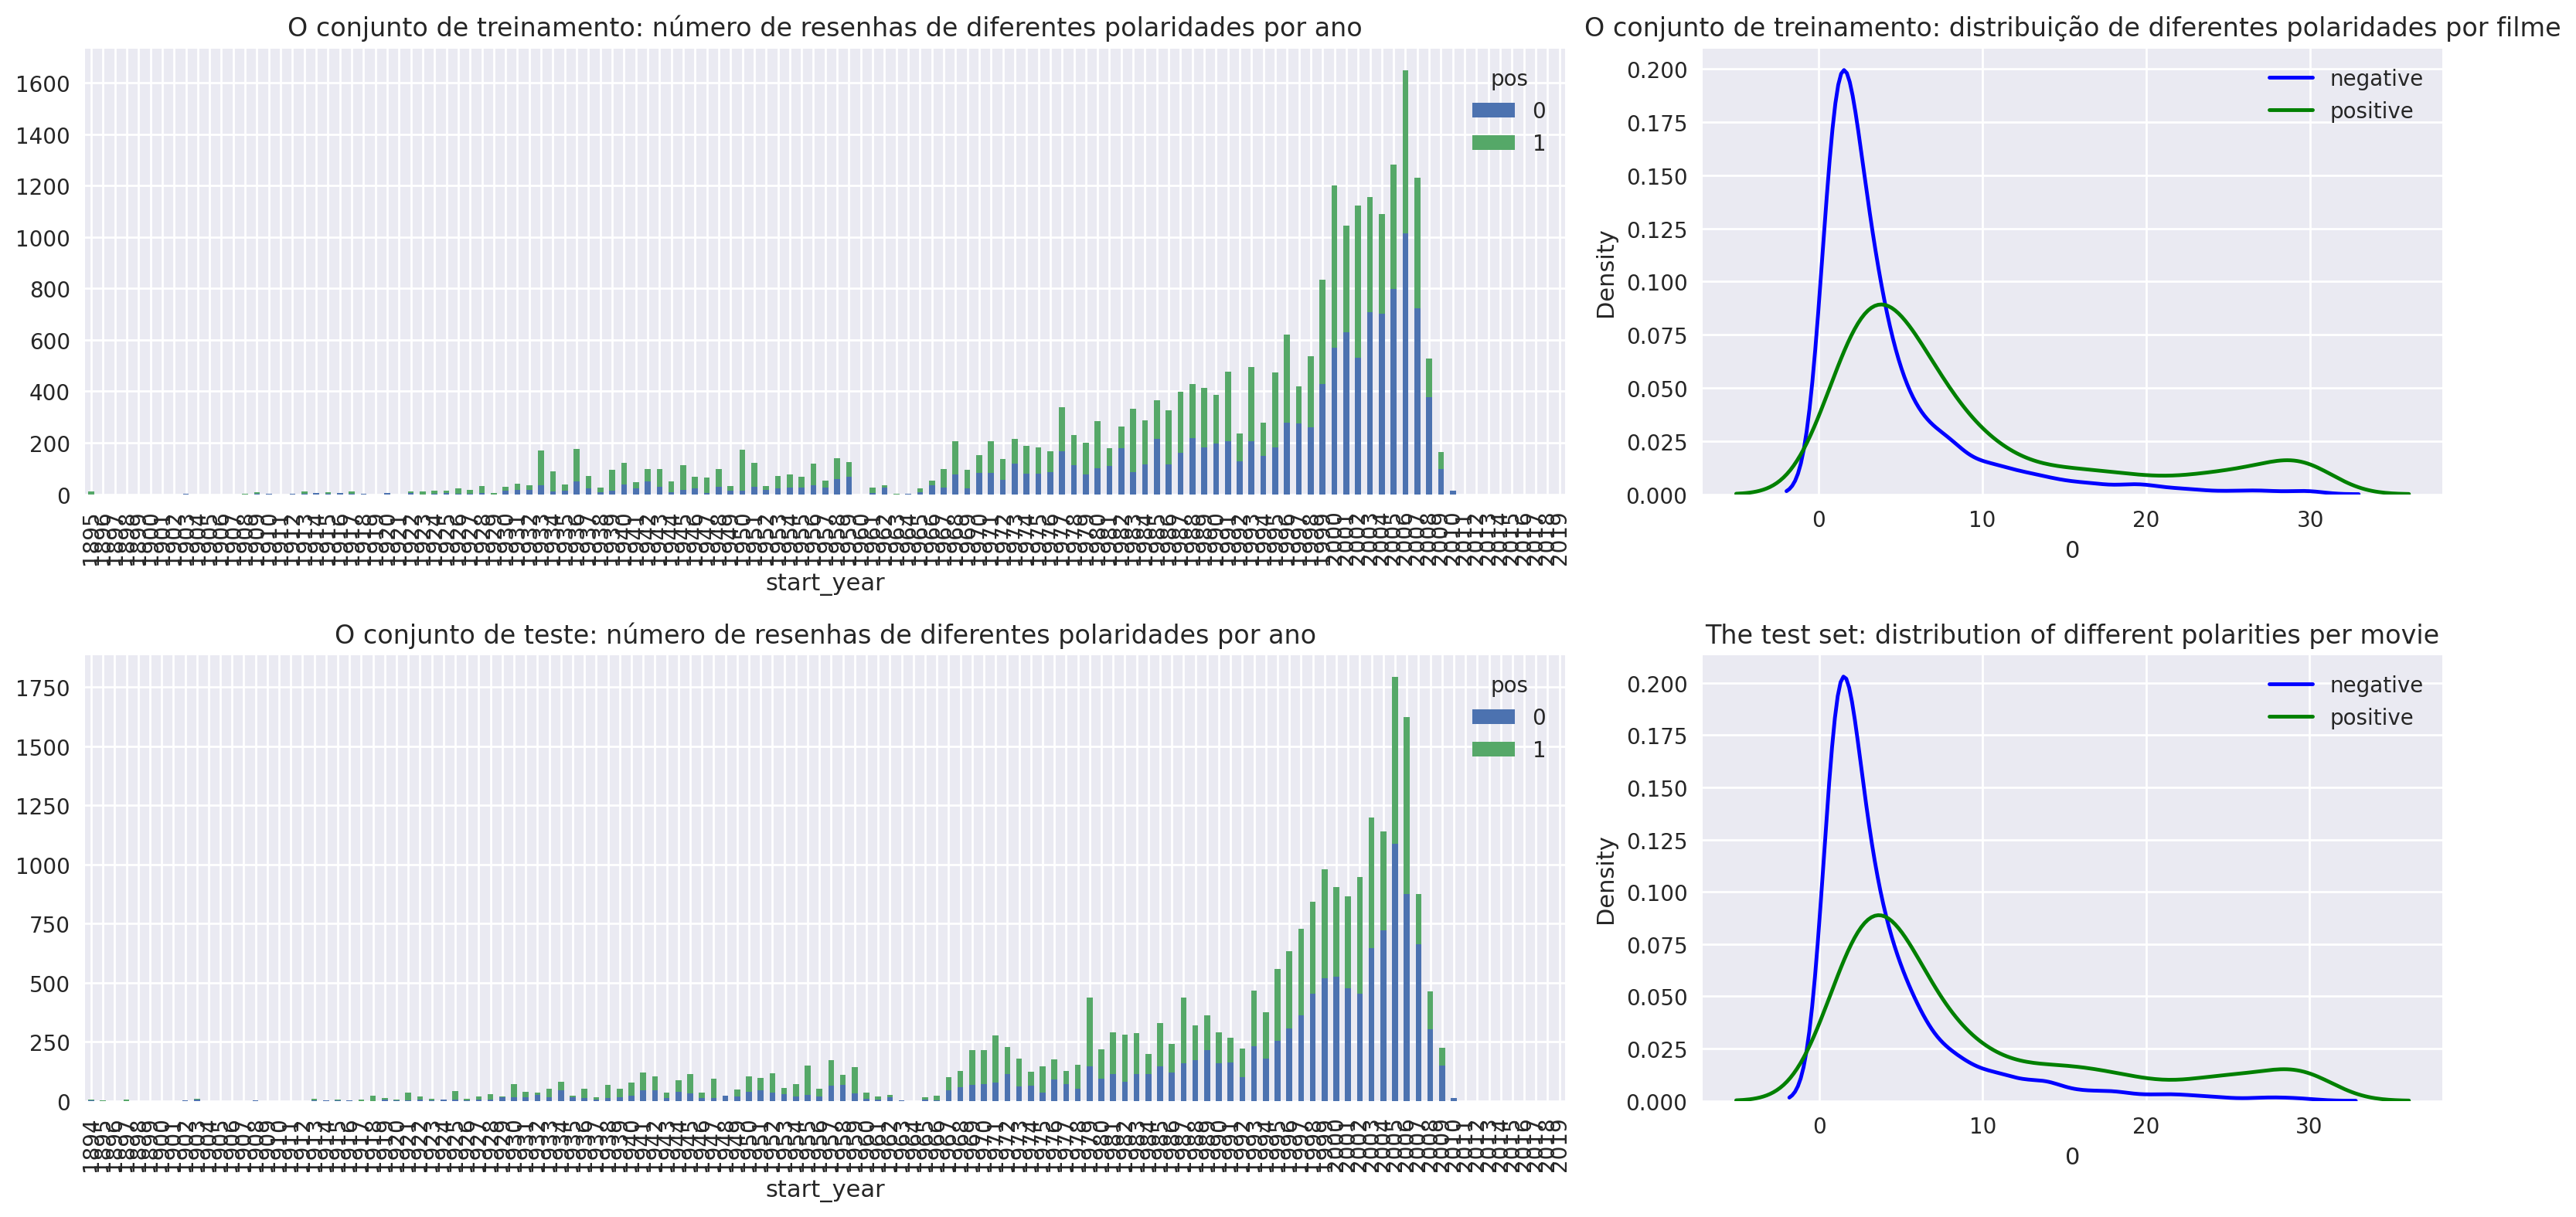

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de treinamento: número de resenhas de diferentes polaridades por ano')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('O conjunto de treinamento: distribuição de diferentes polaridades por filme')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de teste: número de resenhas de diferentes polaridades por ano')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('The test set: distribution of different polarities per movie')

fig.tight_layout()

<div class="alert alert-block alert-warning">

Comparar a polaridade por ano e por filme entre treino e teste é uma verificação útil, e os gráficos mostram que as duas partes têm um formato muito semelhante. Dois pequenos refinamentos deixariam esta figura mais polida: (1) as quatro chamadas de `sns.kdeplot` passam `kernel='epa'`, e a sua saída mostra quatro avisos informando que kernels alternativos não são mais suportados e que um kernel Gaussiano é usado no lugar. O argumento não tem nenhum efeito, então você pode removê-lo para deixar a saída mais limpa. (2) O idioma está misturado: o título do último subplot e os rótulos de legenda `negative`/`positive` estão em inglês, enquanto os demais títulos estão em português. Deixá-los consistentes daria um aspecto mais profissional.

</div>

## Procedimento de Avaliação

Compondo uma rotina de avaliação que pode ser utilizada para todos os modelos deste projeto

In [9]:

import sklearn.metrics as metrics

def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    for type, features, target in (
        ('train', train_features, train_target),
        ('test', test_features, test_target)
    ):

        eval_stats[type] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1 para diferentes limiares
        f1_thresholds = np.arange(0, 1.01, 0.05)

        f1_scores = [
            metrics.f1_score(
                target,
                pred_proba >= threshold,
                zero_division=0
            )
            for threshold in f1_thresholds
        ]

        # Acurácia e F1 usando as previsões padrão do modelo
        eval_stats[type]['Acurácia'] = metrics.accuracy_score(
            target, pred_target
        )

        eval_stats[type]['F1'] = metrics.f1_score(
            target, pred_target, zero_division=0
        )

        # Curva ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(
            target, pred_proba
        )

        roc_auc = metrics.roc_auc_score(target, pred_proba)
        eval_stats[type]['ROC AUC'] = roc_auc

        # Curva de precisão-revocação
        precision, recall, pr_thresholds = metrics.precision_recall_curve(
            target, pred_proba
        )

        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps

        color = 'blue' if type == 'train' else 'green'

        # Gráfico F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)

        ax.plot(
            f1_thresholds,
            f1_scores,
            color=color,
            label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}'
        )

        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(
                np.abs(f1_thresholds - threshold)
            )
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(
                f1_thresholds[closest_value_idx],
                f1_scores[closest_value_idx],
                color=marker_color,
                marker='X',
                markersize=7
            )

        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title('Valor F1')

        # Gráfico ROC
        ax = axs[1]
        ax.plot(
            fpr,
            tpr,
            color=color,
            label=f'{type}, ROC AUC={roc_auc:.2f}'
        )

        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(
                np.abs(roc_thresholds - threshold)
            )
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(
                fpr[closest_value_idx],
                tpr[closest_value_idx],
                color=marker_color,
                marker='X',
                markersize=7
            )

        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title('Curva ROC')

        # Gráfico precisão-revocação
        ax = axs[2]
        ax.plot(
            recall,
            precision,
            color=color,
            label=f'{type}, AP={aps:.2f}'
        )

        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(
                np.abs(pr_thresholds - threshold)
            )
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(
                recall[closest_value_idx],
                precision[closest_value_idx],
                color=marker_color,
                marker='X',
                markersize=7
            )

        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title('PRC')

    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)

    df_eval_stats = df_eval_stats.reindex(
        index=('Acurácia', 'F1', 'APS', 'ROC AUC')
    )

    print(df_eval_stats)

    return

## Normalização

Assumimos que todos os modelos abaixo aceitam textos em letras minúsculas e sem dígitos, sinais de pontuação, etc.

In [10]:
def normalize_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_reviews['review_norm'] = df_reviews['review'].apply(normalize_text)

In [11]:
df_reviews[['review', 'review_norm']].head()

,review,review_norm
0,The pakage implies that Warren Beatty and Gold...,the pakage implies that warren beatty and gold...
1,How the hell did they get this made?! Presenti...,how the hell did they get this made presenting...
2,There is no real story the film seems more lik...,there is no real story the film seems more lik...
3,Um .... a serious film about troubled teens in...,um a serious film about troubled teens in sing...
4,I'm totally agree with GarryJohal from Singapo...,i m totally agree with garryjohal from singapo...


## Treinar / Testar Conjunto

In [12]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


In [13]:
print('Distribuição das classes no conjunto de treino:')
print(train_target.value_counts())
print(train_target.value_counts(normalize=True) * 100)

print('\nDistribuição das classes no conjunto de teste:')
print(test_target.value_counts())
print(test_target.value_counts(normalize=True) * 100)

Distribuição das classes no conjunto de treino:
0    11912
1    11884
Name: pos, dtype: int64
0    50.058833
1    49.941167
Name: pos, dtype: float64

Distribuição das classes no conjunto de teste:
0    11803
1    11732
Name: pos, dtype: int64
0    50.150839
1    49.849161
Name: pos, dtype: float64


#### Conclusão

Após analisar a distribuição das classes, observou-se que o conjunto de dados está balanceado, com 23.715 avaliações negativas (50,10%) e 23.616 avaliações positivas (49,90%).

Essa distribuição também foi mantida nos conjuntos de treino e teste. No treino, as avaliações negativas representam 50,06% e as positivas 49,94%. No teste, as negativas representam 50,15% e as positivas 49,85%.

Portanto, não há um desequilíbrio significativo entre as classes. Isso permite treinar os modelos sem a necessidade de aplicar técnicas de balanceamento, como oversampling ou undersampling. A métrica F1-score continua sendo útil para avaliar o equilíbrio entre precisão e recall, enquanto a acurácia pode ser utilizada como métrica complementar.

## Trabalhando com modelos

### Modelo 0 - Constante

In [14]:
from sklearn.dummy import DummyClassifier

In [15]:
train_features_0 = np.zeros((len(train_target), 1))

test_features_0 = np.zeros((len(test_target), 1))

In [16]:
model_0 = DummyClassifier(strategy='most_frequent')

model_0.fit(train_features_0, train_target)

DummyClassifier(strategy='most_frequent')

          train  test
Acurácia    0.5   0.5
F1          0.0   0.0
APS         0.5   0.5
ROC AUC     0.5   0.5


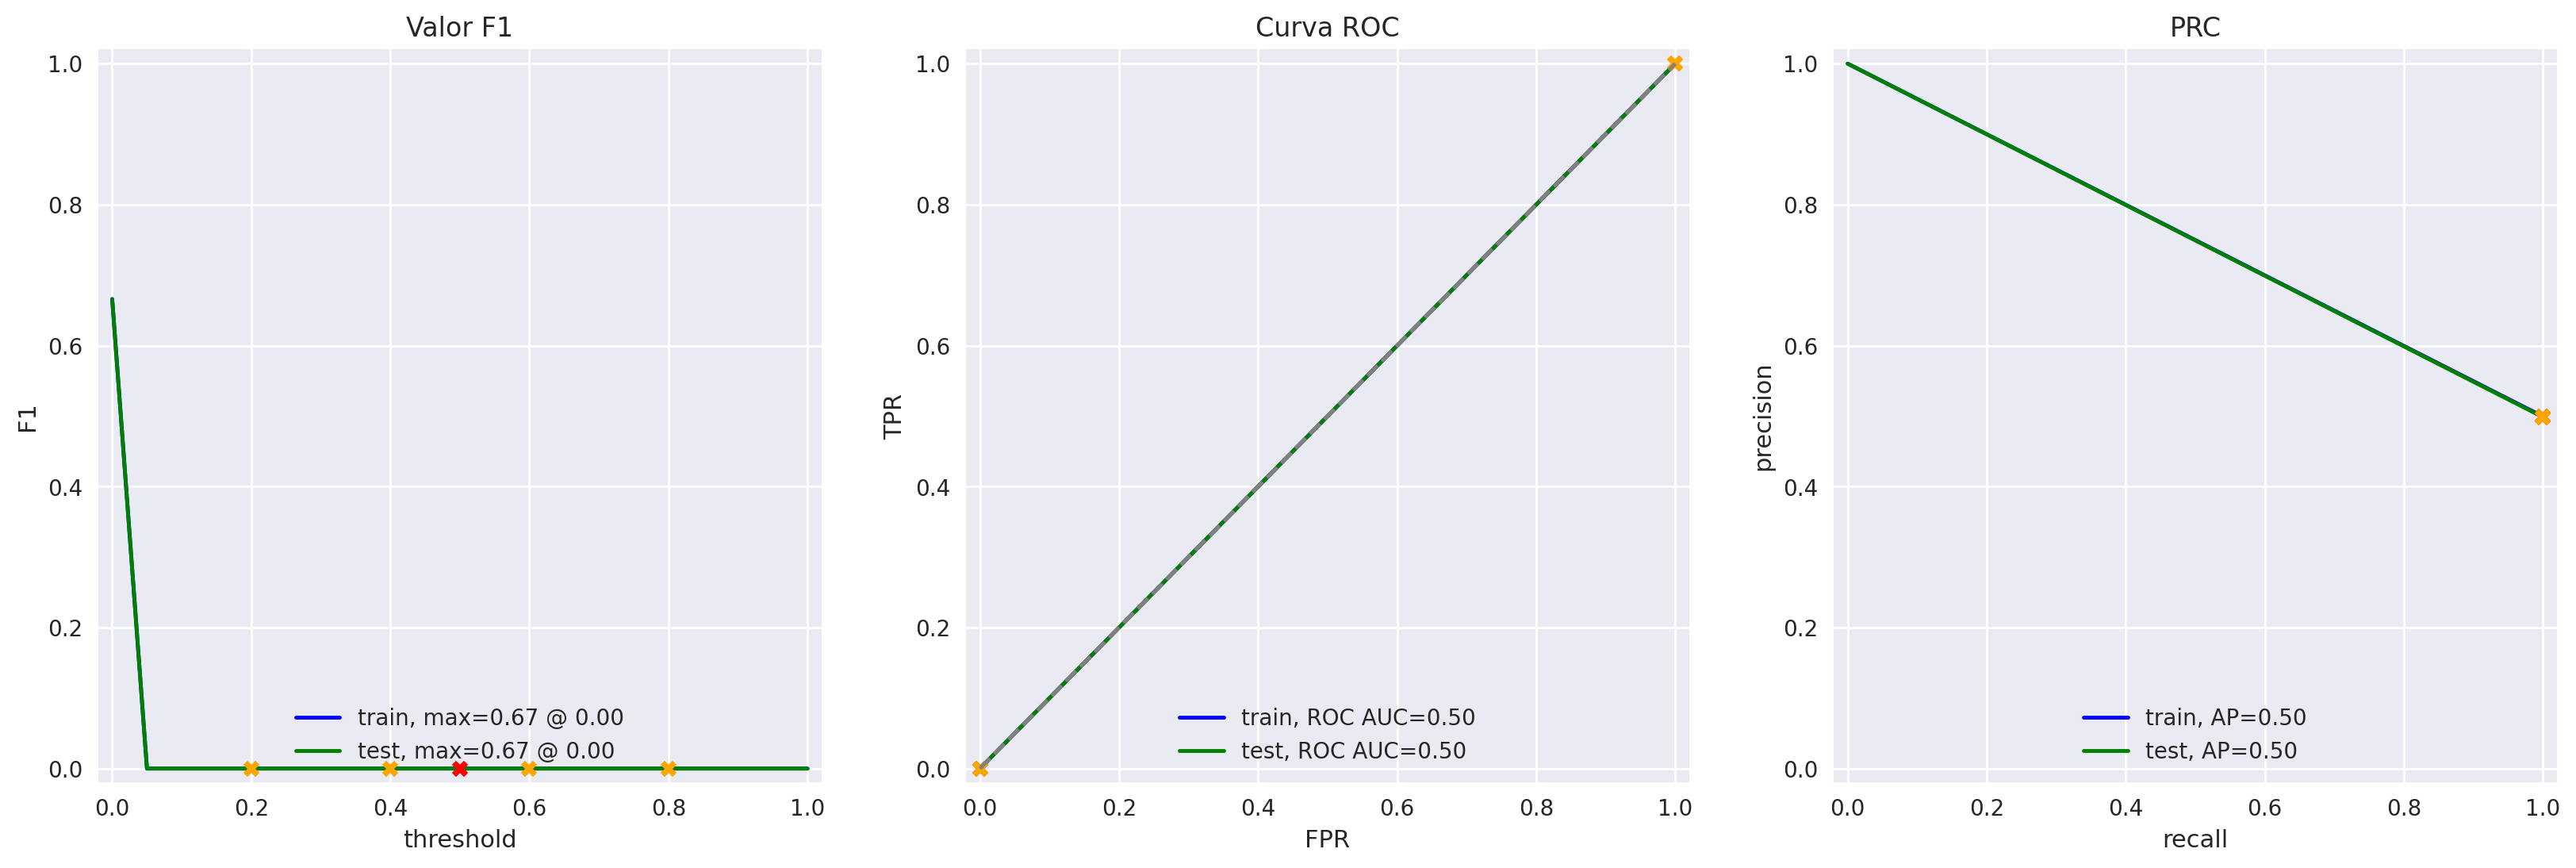

In [17]:
evaluate_model(
    model_0,
    train_features_0,
    train_target,
    test_features_0,
    test_target
)

### Modelo 1 - NLTK, TF-IDF e Regressão Linear

TF-IDF

In [18]:
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords

In [19]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

tfidf_vectorizer_1 = TfidfVectorizer(stop_words=stop_words)

train_features_1 = tfidf_vectorizer_1.fit_transform(
    df_reviews_train['review_norm']
)

test_features_1 = tfidf_vectorizer_1.transform(
    df_reviews_test['review_norm']
)

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/student/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [20]:
model_1 = LogisticRegression(
    random_state=12345,
    max_iter=1000
)

model_1.fit(train_features_1, train_target)

# Compatibilidade com a seção "Minhas Resenhas" do notebook
model_2 = model_1
tfidf_vectorizer_2 = tfidf_vectorizer_1

          train  test
Acurácia   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


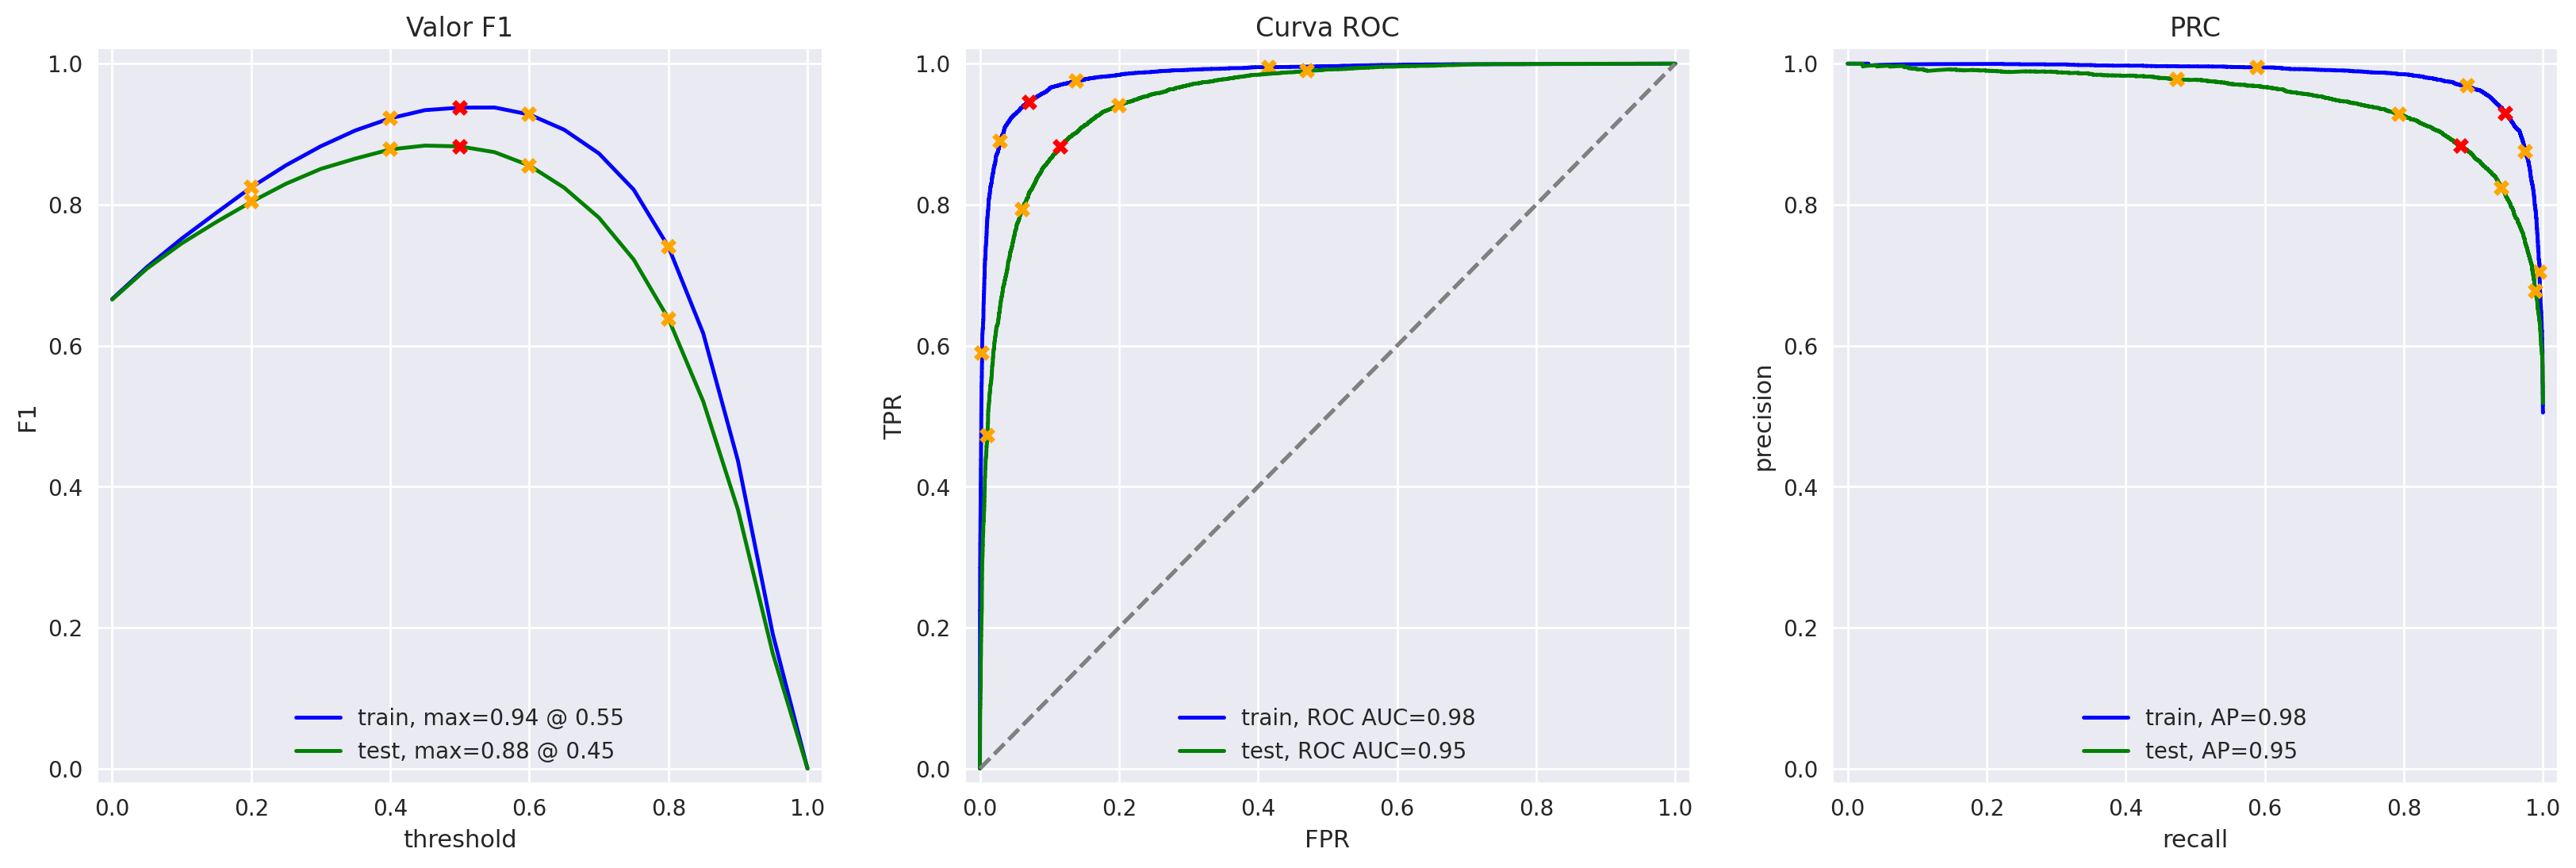

In [21]:
evaluate_model(model_1, train_features_1, train_target, test_features_1, test_target)

### Modelo 3 - spaCy, TF-IDF e Regressão Linear

In [22]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [23]:
def text_preprocessing_3(text):
    
    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
    tokens = [token.lemma_ for token in doc]
    
    return ' '.join(tokens)

In [24]:
train_reviews_3 = df_reviews_train['review_norm'].apply(text_preprocessing_3)

test_reviews_3 = df_reviews_test['review_norm'].apply(text_preprocessing_3)

tfidf_vectorizer_3 = TfidfVectorizer(stop_words='english')

train_features_3 = tfidf_vectorizer_3.fit_transform(train_reviews_3)

test_features_3 = tfidf_vectorizer_3.transform(test_reviews_3)

In [25]:
model_3 = LogisticRegression(
    random_state=12345,
    max_iter=1000
)

model_3.fit(train_features_3, train_target)

LogisticRegression(max_iter=1000, random_state=12345)

          train  test
Acurácia   0.93  0.87
F1         0.93  0.87
APS        0.98  0.94
ROC AUC    0.98  0.95


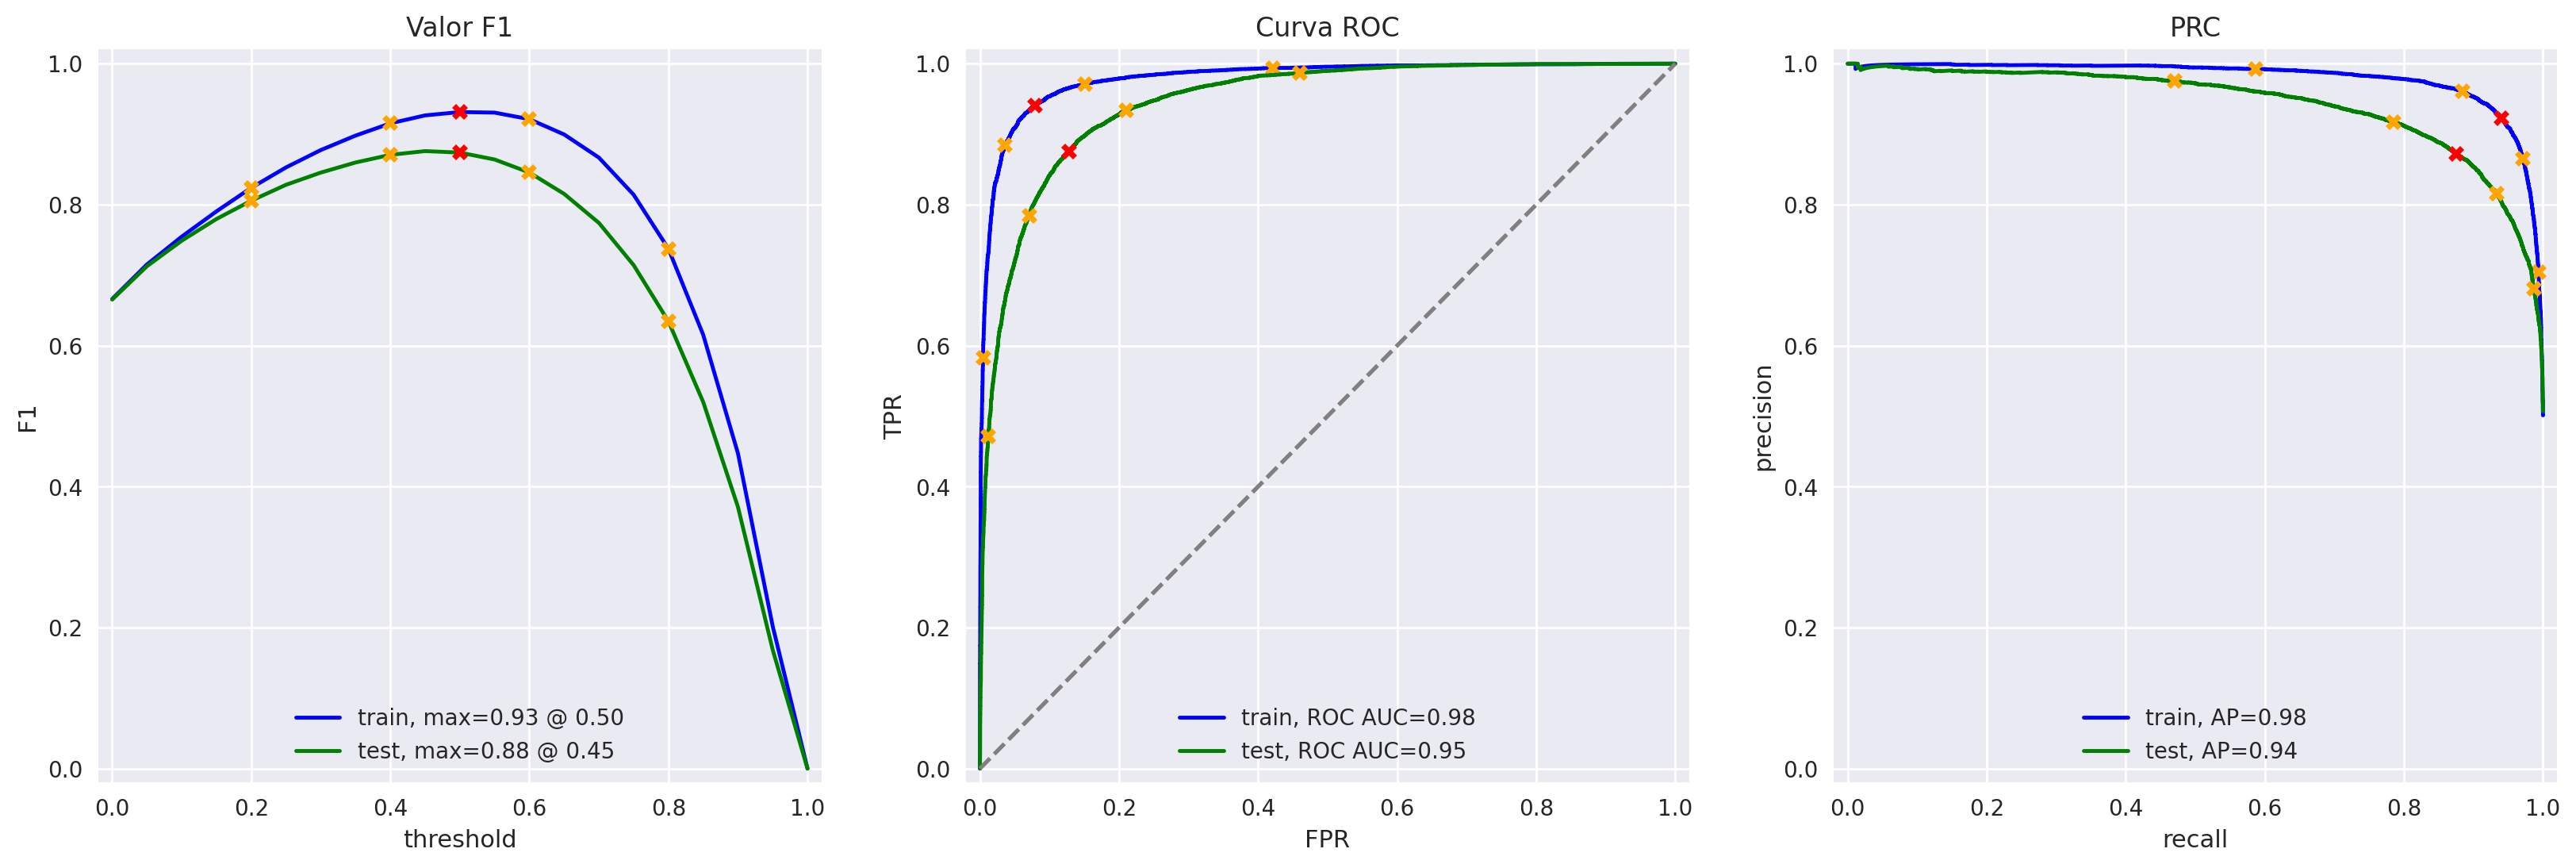

In [26]:
evaluate_model(
    model_3,
    train_features_3,
    train_target,
    test_features_3,
    test_target
)

### Modelo 4 - SpaCy, TF-IDF e LGBMClassifier

In [27]:
from lightgbm import LGBMClassifier

In [28]:
tfidf_vectorizer_4 = tfidf_vectorizer_3

train_features_4 = train_features_3

test_features_4 = test_features_3

In [29]:
model_4 = LGBMClassifier(
    random_state=12345,
    n_estimators=100
)

model_4.fit(train_features_4, train_target)

LGBMClassifier(random_state=12345)

          train  test
Acurácia   0.91  0.86
F1         0.91  0.86
APS        0.97  0.93
ROC AUC    0.97  0.93


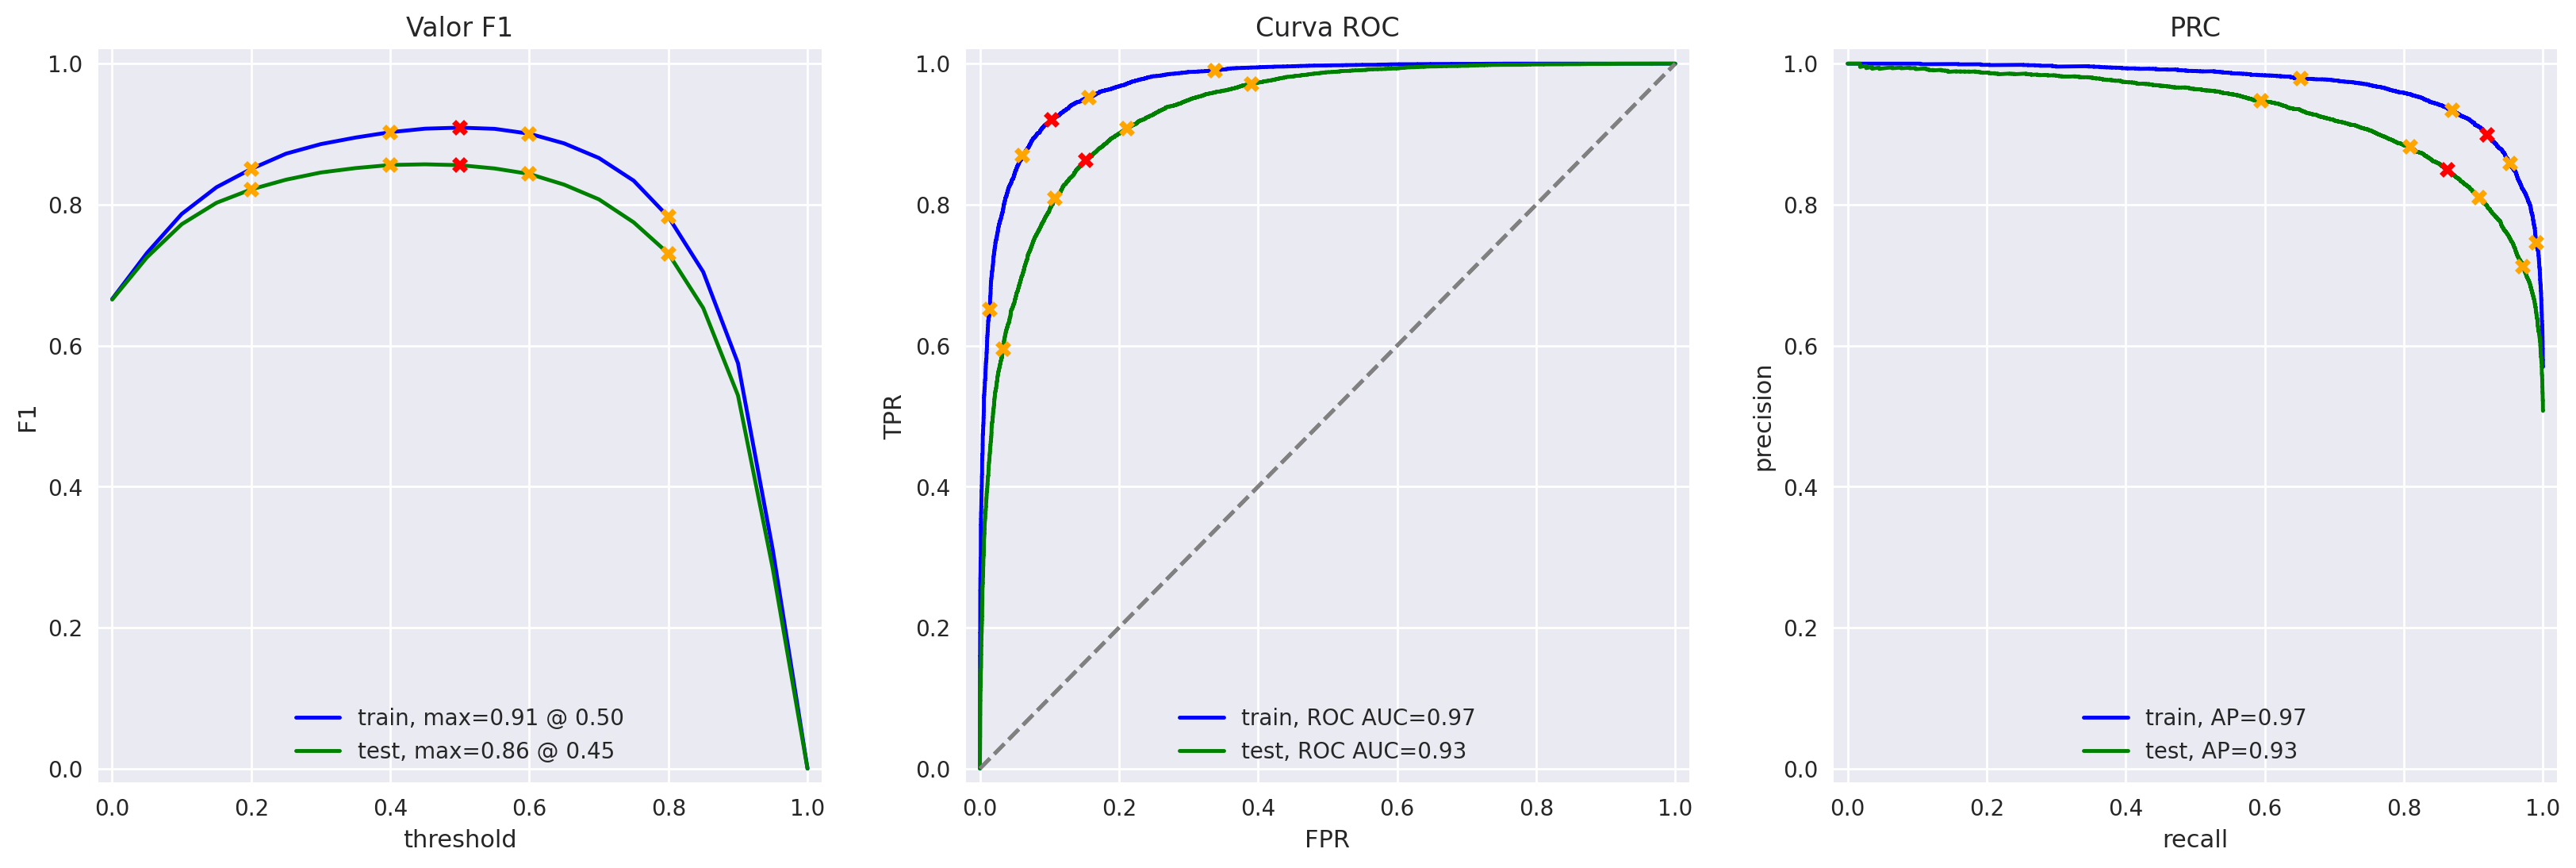

In [30]:
evaluate_model(
    model_4,
    train_features_4,
    train_target,
    test_features_4,
    test_target
)

## Minhas Resenhas

In [31]:
my_reviews = pd.DataFrame([
    'I simply did not like it. It is not my kind of movie.',
    'Well, I was bored and fell asleep halfway through the movie.',
    'I was really fascinated by the movie.',
    'The actors seemed too old and uninterested, and yet they were paid to participate in the movie. What a shameless waste of money.',
    'I did not expect the remake to be so good! The writers really cared about the original material.',
    'The movie has its pros and cons, but I feel that overall it is a decent movie. I can imagine watching it again.',
    'What a terrible attempt at comedy. Not a single joke works, everyone acts annoyingly and loudly, not even children will enjoy this!',
    'Releasing it on Netflix was a bold move, and I really appreciate being able to watch episode after episode of this exciting and intelligent new drama.'
], columns=['review'])

my_reviews['review_norm'] = my_reviews['review'].apply(normalize_text)

### Modelo 2

In [32]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_1.predict_proba(
    tfidf_vectorizer_1.transform(texts)
)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}: {review}')

0.14: i simply did not like it it is not my kind of movie
0.16: well i was bored and fell asleep halfway through the movie
0.54: i was really fascinated by the movie
0.03: the actors seemed too old and uninterested and yet they were paid to participate in the movie what a
0.13: i did not expect the remake to be so good the writers really cared about the original material
0.43: the movie has its pros and cons but i feel that overall it is a decent movie i can imagine watching 
0.13: what a terrible attempt at comedy not a single joke works everyone acts annoyingly and loudly not ev
0.85: releasing it on netflix was a bold move and i really appreciate being able to watch episode after ep


### Modelo 3

In [35]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_3.predict_proba(tfidf_vectorizer_3.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.21:  i simply did not like it it is not my kind of movie
0.07:  well i was bored and fell asleep halfway through the movie
0.62:  i was really fascinated by the movie
0.03:  the actors seemed too old and uninterested and yet they were paid to participate in the movie what a
0.11:  i did not expect the remake to be so good the writers really cared about the original material
0.36:  the movie has its pros and cons but i feel that overall it is a decent movie i can imagine watching 
0.13:  what a terrible attempt at comedy not a single joke works everyone acts annoyingly and loudly not ev
0.96:  releasing it on netflix was a bold move and i really appreciate being able to watch episode after ep


### Modelo 4

In [34]:
texts = my_reviews['review_norm']

tfidf_vectorizer_4 = tfidf_vectorizer_3
my_reviews_pred_prob = model_4.predict_proba(tfidf_vectorizer_4.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.61:  i simply did not like it it is not my kind of movie
0.27:  well i was bored and fell asleep halfway through the movie
0.62:  i was really fascinated by the movie
0.07:  the actors seemed too old and uninterested and yet they were paid to participate in the movie what a
0.64:  i did not expect the remake to be so good the writers really cared about the original material
0.57:  the movie has its pros and cons but i feel that overall it is a decent movie i can imagine watching 
0.18:  what a terrible attempt at comedy not a single joke works everyone acts annoyingly and loudly not ev
0.88:  releasing it on netflix was a bold move and i really appreciate being able to watch episode after ep


## Conclusões

Neste projeto, o objetivo foi desenvolver modelos de Machine Learning capazes de classificar automaticamente resenhas de filmes como positivas ou negativas, utilizando técnicas de Processamento de Linguagem Natural (NLP) e dados do IMDB.

Durante a análise exploratória, identifiquei que as classes estão praticamente balanceadas, com 23.715 avaliações negativas e 23.616 positivas. Essa distribuição reduz o risco de viés causado pelo desbalanceamento e permite utilizar o F1-score como métrica de avaliação.

Foram desenvolvidos e avaliados três modelos principais:

Regressão Logística com TF-IDF: F1 de 0,88.

Regressão Logística com spaCy e TF-IDF: F1 de 0,87.

LightGBM com spaCy e TF-IDF: F1 de 0,86.

Todos atingiram a meta estabelecida de F1 igual ou superior a 0,85. A Regressão Logística com TF-IDF apresentou o melhor resultado, possivelmente por preservar as palavras originais e trabalhar bem com características textuais esparsas. A lematização pode reduzir algumas distinções importantes do vocabulário, enquanto o LightGBM, por utilizar árvores de decisão, pode ter mais dificuldade para trabalhar com esse tipo de representação. Também foi observado um leve overfitting nos modelos, indicando uma diferença entre o desempenho no treinamento e no teste.

Para verificar o comportamento dos classificadores em novos exemplos, foram utilizadas oito resenhas próprias em inglês. Os três modelos concordaram em cinco classificações: nas resenhas 2, 3, 4, 7 e 8. Nas resenhas 1, 5 e 6, as duas Regressões Logísticas apresentaram resultados iguais, enquanto o LightGBM divergiu. Na primeira, classificou incorretamente uma opinião negativa como positiva; na quinta, identificou corretamente uma opinião positiva que os outros dois modelos classificaram como negativa; e, na sexta, que apresentava sentimentos mistos, classificou a avaliação como positiva, enquanto as Regressões Logísticas a classificaram como negativa.

Esses resultados são parcialmente coerentes com as métricas do conjunto de teste, no qual a Regressão Logística com TF-IDF apresentou o melhor F1. Entretanto, as previsões individuais demonstram que um bom desempenho nas métricas não garante acertos em todos os exemplos. Isso pode ser explicado pela amostra muito pequena de apenas oito resenhas, pela presença de negações e opiniões mistas e pela cobertura do vocabulário aprendido durante o treinamento. Expressões como "did not like" e "did not expect" podem perder parte do seu significado quando palavras de negação, como "not", são removidas durante o pré-processamento. Além disso, palavras e combinações ausentes do vocabulário aprendido pelo TF-IDF não contribuem diretamente para a classificação.

O baseline constante, com F1 de 0,00, demonstra que simplesmente prever uma única classe não é suficiente para resolver o problema, reforçando a importância dos modelos treinados.

Concluindo, recomendo a utilização da Regressão Logística com TF-IDF, pois apresentou o melhor desempenho geral no conjunto de teste e atingiu a meta estabelecida pelo projeto. O modelo demonstra potencial para auxiliar a Film Junky Union na identificação e categorização automática de resenhas positivas e negativas.